In [1]:
import numpy as np
import os
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torchvision
from torchvision import transforms as T
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

In [2]:
images = sorted(os.listdir("./datasets/PennFudanPed/PNGImages"))
masks = sorted(os.listdir("./datasets/PennFudanPed/PedMasks"))

In [3]:
idx = 0
img = Image.open("./datasets/PennFudanPed/PNGImages/" + images[idx]).convert("RGB")
mask = Image.open("./datasets/PennFudanPed/PedMasks/" + masks[idx])

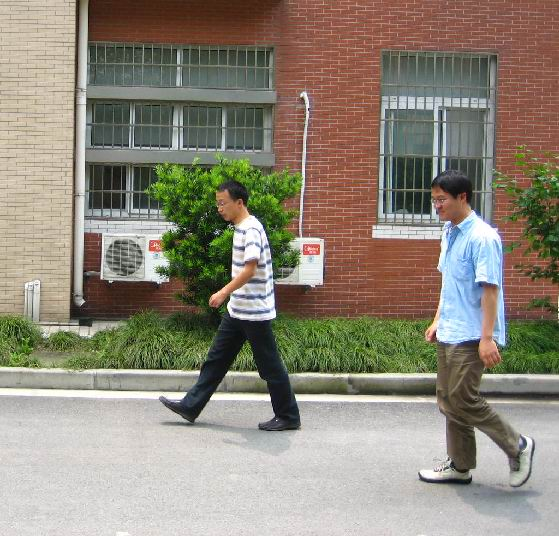

In [4]:
img

In [5]:
np.unique(mask)

array([0, 1, 2], dtype=uint8)

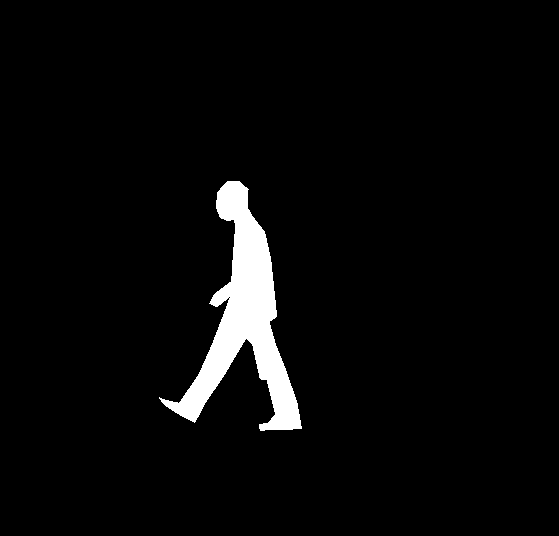

In [6]:
Image.fromarray(np.array(mask) == 1)

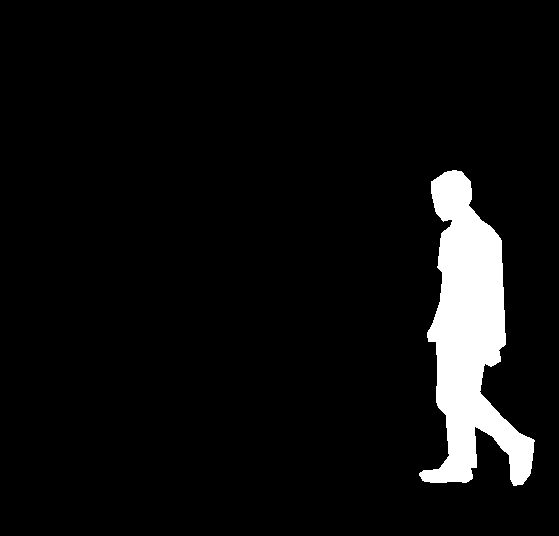

In [7]:
Image.fromarray(np.array(mask) == 2)

In [8]:
class CustDat(torch.utils.data.Dataset):
    def __init__(self , images , masks):
        self.imgs = images
        self.masks = masks
        
    def __getitem__(self , idx):
        img = Image.open("./datasets/PennFudanPed/PNGImages/" + self.imgs[idx]).convert("RGB")
        mask = Image.open("./datasets/PennFudanPed/PedMasks/" + self.masks[idx])
        mask = np.array(mask)
        obj_ids = np.unique(mask)
        obj_ids = obj_ids[1:]
        num_objs = len(obj_ids)
        masks = np.zeros((num_objs , mask.shape[0] , mask.shape[1]))
        for i in range(num_objs):
            masks[i][mask == i+1] = True
        boxes = []
        for i in range(num_objs):
            pos = np.where(masks[i])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            boxes.append([xmin , ymin , xmax , ymax])
        boxes = torch.as_tensor(boxes , dtype = torch.float32)
        labels = torch.ones((num_objs,) , dtype = torch.int64)
        masks = torch.as_tensor(masks , dtype = torch.uint8)
        
        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["masks"] = masks
        return T.ToTensor()(img) , target
    
    def __len__(self):
        return len(self.imgs)

In [9]:
model = torchvision.models.detection.maskrcnn_resnet50_fpn()
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features , 2)
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer = 256
model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask , hidden_layer , 2)

In [10]:
transform = T.ToTensor()

In [11]:
def custom_collate(data):
  return data

In [12]:
images = sorted(os.listdir("./datasets/PennFudanPed/PNGImages"))
masks = sorted(os.listdir("./datasets/PennFudanPed/PedMasks"))
num = int(0.9 * len(images))
num = num if num % 2 == 0 else num + 1
train_imgs_inds = np.random.choice(range(len(images)) , num , replace = False)
val_imgs_inds = np.setdiff1d(range(len(images)) , train_imgs_inds)
train_imgs = np.array(images)[train_imgs_inds]
val_imgs = np.array(images)[val_imgs_inds]
train_masks = np.array(masks)[train_imgs_inds]
val_masks = np.array(masks)[val_imgs_inds]

In [13]:
train_dl = torch.utils.data.DataLoader(CustDat(train_imgs , train_masks) , 
                                 batch_size = 2 , 
                                 shuffle = True , 
                                 collate_fn = custom_collate , 
                                 num_workers = 0 , 
                                 pin_memory = True if torch.cuda.is_available() else False)
val_dl = torch.utils.data.DataLoader(CustDat(val_imgs , val_masks) , 
                                 batch_size = 2 , 
                                 shuffle = True , 
                                 collate_fn = custom_collate , 
                                 num_workers = 0 , 
                                 pin_memory = True if torch.cuda.is_available() else False)

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [15]:
model.to(device)

MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=1e-05)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=1e-05)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=1e-05)
          (relu):

In [16]:
params = [p for p in model.parameters() if p.requires_grad]

In [17]:
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

In [18]:
all_train_losses = []
all_val_losses = []
flag = False
for epoch in range(30):
    train_epoch_loss = 0
    val_epoch_loss = 0
    model.train()
    for i , dt in enumerate(train_dl):
        imgs = [dt[0][0].to(device) , dt[1][0].to(device)]
        targ = [dt[0][1] , dt[1][1]]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targ]
        loss = model(imgs , targets)
        if not flag:
            print(loss)
            flag = True
        losses = sum([l for l in loss.values()])
        train_epoch_loss += losses.cpu().detach().numpy()
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
    all_train_losses.append(train_epoch_loss)
    with torch.no_grad():
        for j , dt in enumerate(val_dl):
            imgs = [dt[0][0].to(device) , dt[1][0].to(device)]
            targ = [dt[0][1] , dt[1][1]]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targ]
            loss = model(imgs , targets)
            losses = sum([l for l in loss.values()])
            val_epoch_loss += losses.cpu().detach().numpy()
        all_val_losses.append(val_epoch_loss)
    print(epoch , "  " , train_epoch_loss , "  " , val_epoch_loss)

{'loss_classifier': tensor(0.6458, grad_fn=<NllLossBackward0>), 'loss_box_reg': tensor(0.0051, grad_fn=<DivBackward0>), 'loss_mask': tensor(2.5882, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_objectness': tensor(0.6916, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>), 'loss_rpn_box_reg': tensor(0.0168, grad_fn=<DivBackward0>)}
0    88.64364    6.79646
1    65.60537    5.3652472
2    50.067078    3.8947186
3    42.96961    3.8081632
4    37.18473    3.367862
5    33.17803    3.1299958
6    31.644373    3.3152628
7    29.199379    2.812188
8    27.407642    2.7395525
9    26.75804    2.6089413
10    24.962158    2.5272405
11    23.605797    2.7335901
12    23.142519    2.4547825
13    23.487812    2.738752
14    21.767843    2.3990242
15    20.542906    2.3457792
16    19.522463    2.4762876
17    22.208378    2.6175814
18    19.480453    2.4110467
19    18.242435    2.349502
20    17.89448    2.537631
21    16.610508    2.3762085
22    17.325483    2.4558966
23    16.60293 

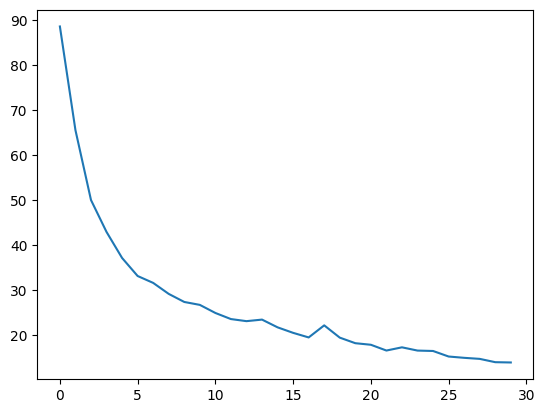

In [19]:
plt.plot(all_train_losses)

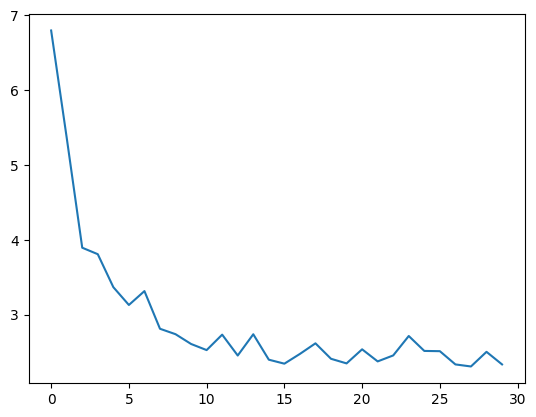

In [20]:
plt.plot(all_val_losses)

In [21]:
# !wget https://cdn.pixabay.com/photo/2018/09/18/21/08/couple-3687274_960_720.jpg

--2026-11-04 06:06:08--  https://cdn.pixabay.com/photo/2018/09/18/21/08/couple-3687274_960_720.jpg
Resolving cdn.pixabay.com (cdn.pixabay.com)... 2a06:98c1:3103::ac40:93a0, 2a06:98c1:3100::6812:2860, 172.64.147.160, ...
Connecting to cdn.pixabay.com (cdn.pixabay.com)|2a06:98c1:3103::ac40:93a0|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 207783 (203K) [image/jpeg]
Saving to: 'couple-3687274_960_720.jpg'

     0K .......... .......... .......... .......... .......... 24%  398K 0s
    50K .......... .......... .......... .......... .......... 49%  412K 0s
   100K .......... .......... .......... .......... .......... 73%  407K 0s
   150K .......... .......... .......... .......... .......... 98% 19.1M 0s
   200K ..                                                    100% 23.0M=0.4s

2026-11-04 06:06:09 (544 KB/s) - 'couple-3687274_960_720.jpg' saved [207783/207783]



In [23]:
model.eval()
img = Image.open("./images/couple-3687274_960_720.jpg")
transform = T.ToTensor()
ig = transform(img)
with torch.no_grad():
    pred = model([ig.to(device)])

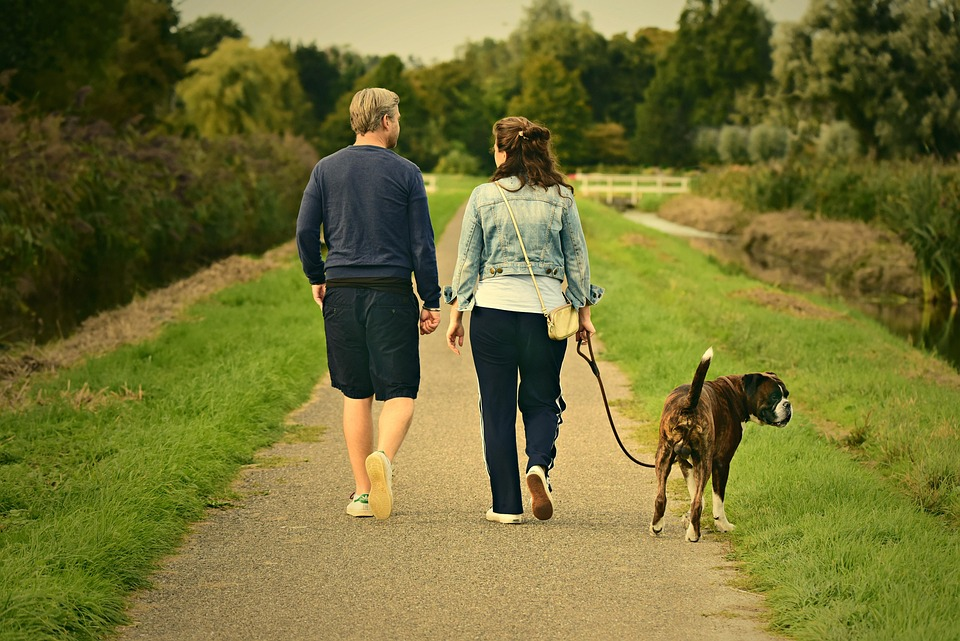

In [24]:
img

In [25]:
pred

[{'boxes': tensor([[297.1992,  81.8312, 450.9263, 515.8429],
          [439.5941, 114.0146, 602.4331, 514.4284],
          [653.8072, 353.8455, 756.9635, 536.0640],
          [655.8403, 384.5797, 696.4702, 508.0129],
          [323.9392, 105.4116, 689.4222, 514.1500]]),
  'labels': tensor([1, 1, 1, 1, 1]),
  'scores': tensor([0.9991, 0.9990, 0.8901, 0.6377, 0.4465]),
  'masks': tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            ...,
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.]]],
  
  
          [[[0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            ...,
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.],
            [0., 0., 0.,  ..., 0., 0., 0.]]],
  
  
          [[[0., 0., 0.,  ..., 0., 0., 0.],

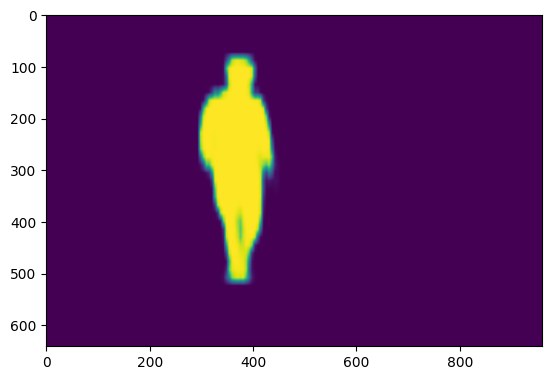

In [26]:
plt.imshow((pred[0]["masks"][0].cpu().detach().numpy() * 255).astype("uint8").squeeze())

In [27]:
img.size

(960, 641)